# Day 8: Continuous MLOps Monitoring, Statistical Drift Detection & Automated Retraining Framework
**Project:** Wine Quality Prediction (Cortez et al. UCI Machine Learning Repository)
**Author:** ML Engineering & Production Deployment Team
**Date:** October 25, 2026
**Tech Stack:** Python 3.14, Scikit-learn, Scipy Stats, FastAPI, Pydantic v2, Streamlit, Pytest, Plotly, Seaborn, Matplotlib, Joblib

## Objectives for Day 8
1. **Statistical Covariate Shift & Data Drift Engine (`src/drift_monitoring.py`):**
   - Quantile Population Stability Index (PSI) with monotonic edge handling and standard risk thresholds (Green < 0.10, Amber 0.10-0.25, Red >= 0.25).
   - Two-sample Kolmogorov-Smirnov (K-S) goodness-of-fit hypothesis testing with exact asymptotic p-values.
   - Wasserstein-1 (Earth Mover's) Distance and normalized variance shift quantification.
2. **Domain Enological Vintage Simulation:**
   - Realistic multi-variate harvest shift models: Climate Warming (elevated alcohol, lowered fixed acidity, higher pH), Cool Rainy Harvest (diluted alcohol, sulfur surge), and Instrument Calibration Bias.
3. **Multivariate Chemical Anomaly Screening (Isolation Forest):**
   - Pre-inference contamination screening to flag adulterated, spoiled, or aberrant laboratory batches.
4. **Longitudinal Sommelier Auditing & Concept Drift Tracking:**
   - Delayed ground-truth sensory panel evaluation simulating quarterly sommelier audits to detect concept drift ($P(Y|X)$ shifts).
5. **Closed-Loop Retraining & Champion-Challenger Tournament:**
   - Automated retraining trigger rules, Stratified 5-Fold CV training on augmented harvest corpus, side-by-side tournament evaluation, and hot model promotion.
6. **Production Serving Extensions (`src/production_service.py`):**
   - Live monitoring endpoints: `GET /metrics/drift` and `POST /audit/evaluate`.
7. **Interactive Dashboard Monitoring Suite (`src/interactive_dashboard.py`):**
   - New real-time Vintage Drift & MLOps Monitoring control center in Streamlit.
8. **Automated Comprehensive Pytest Verification (`tests/test_drift_monitoring.py`):**
   - 10 new unit and integration tests expanding test coverage to 32 automated tests (100% pass rate).

In [1]:
import sys
import os
import json
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown

warnings.filterwarnings('ignore')

# Ensure repository root is on sys.path
REPO_ROOT = Path('.').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.data_loader import load_wine_data
from src.feature_engineering import create_binned_targets, create_engineered_features, get_stratified_train_test_split
from src.drift_monitoring import (
    calculate_psi,
    compute_kolmogorov_smirnov,
    compute_wasserstein_distance,
    compute_feature_drift,
    compute_dataset_drift_summary,
    simulate_vintage_drift,
    MultivariateAnomalyDetector,
    AuditPerformanceTracker,
    DriftRetrainingPipeline,
    RAW_PHYSICOCHEMICAL_FEATURES,
    ALL_MODEL_FEATURES,
    PSI_THRESHOLD_GREEN,
    PSI_THRESHOLD_AMBER
)
from src.production_service import get_test_client
import joblib

print('Day 8 environment initialized successfully!')

Day 8 environment initialized successfully!


## 1. Baseline Reference Ingestion & Physicochemical Profile
We load the historical baseline training corpus (Cortez et al. UCI Red Wine Dataset, 1,599 samples) which serves as the empirical distribution benchmark against which all incoming commercial harvest batches are evaluated.

In [2]:
df_raw = load_wine_data('red')
df_binned = create_binned_targets(df_raw)
df_feat = create_engineered_features(df_binned)
X = df_feat.drop(columns=['quality', 'binary_quality', 'three_class_quality'])
y = df_feat['binary_quality']
X_train, X_test, y_train, y_test = get_stratified_train_test_split(X, y)

print(f'Baseline Reference Corpus: {len(df_raw)} samples across {len(RAW_PHYSICOCHEMICAL_FEATURES)} physicochemical features.')
print(f'Engineered Feature Dimensionality: {X_train.shape[1]} features.')
df_raw[RAW_PHYSICOCHEMICAL_FEATURES].describe().round(3).T[['mean', 'std', 'min', '50%', 'max']]

Baseline Reference Corpus: 1599 samples across 11 physicochemical features.
Engineered Feature Dimensionality: 16 features.


,mean,std,min,50%,max
fixed acidity,8.320,1.741,4.600,7.900,15.900
volatile acidity,0.528,0.179,0.120,0.520,1.580
citric acid,0.271,0.195,0.000,0.260,1.000
residual sugar,2.539,1.410,0.900,2.200,15.500
chlorides,0.087,0.047,0.012,0.079,0.611
free sulfur dioxide,15.875,10.460,1.000,14.000,72.000
total sulfur dioxide,46.468,32.895,6.000,38.000,289.000
density,0.997,0.002,0.990,0.997,1.004
pH,3.311,0.154,2.740,3.310,4.010
sulphates,0.658,0.170,0.330,0.620,2.000


## 2. Statistical Covariate Shift & Population Stability Index (PSI)
The Population Stability Index (PSI) quantifies divergence between empirical reference and target distributions:
$$\text{PSI} = \sum_{i=1}^k \left( P_{\text{target}, i} - P_{\text{ref}, i} \right) \times \ln\left( \frac{P_{\text{target}, i}}{P_{\text{ref}, i}} \right)$$

Regulatory & Industrial Risk Bands:
- $\text{PSI} < 0.10$: **Stable (Green)** - No actionable distribution shift.
- $0.10 \le \text{PSI} < 0.25$: **Warning (Amber)** - Moderate shift; inspection recommended.
- $\text{PSI} \ge 0.25$: **Action Required (Red)** - Significant covariate shift; retrain model.

In [3]:
# Simulate climate warming harvest vintage (+0.85% alcohol, -0.65 g/dm3 tartaric acid, +0.12 pH)
vintage_warming = simulate_vintage_drift(df_raw, scenario='climate_warming', severity=1.0)

# Compute multi-metric drift scorecard
drift_summary = compute_dataset_drift_summary(df_raw, vintage_warming)
display(drift_summary.sort_values(by='PSI', ascending=False))

red_count = (drift_summary['Alert_Level'] == 'RED').sum()
amber_count = (drift_summary['Alert_Level'] == 'AMBER').sum()
green_count = (drift_summary['Alert_Level'] == 'GREEN').sum()
print(f'Drift Summary: {green_count} Green (Stable), {amber_count} Amber (Warning), {red_count} Red (Severe Drift)')

,Feature,PSI,KS_Statistic,KS_P_Value,Wasserstein_Dist,Norm_Wasserstein,Drift_Status,Alert_Level
10,alcohol,1.4212,0.4053,8.822456e-118,0.8581,0.8055,Severe Drift,RED
8,pH,0.5739,0.3408,1.035840e-82,0.1192,0.7723,Severe Drift,RED
1,volatile acidity,0.3210,0.2051,7.615370e-30,0.0893,0.4989,Severe Drift,RED
0,fixed acidity,0.2887,0.2289,4.029088e-37,0.6487,0.3727,Severe Drift,RED
2,citric acid,0.0000,0.0000,1.000000e+00,0.0000,0.0000,Stable,GREEN
3,residual sugar,0.0000,0.0000,1.000000e+00,0.0000,0.0000,Stable,GREEN
4,chlorides,0.0000,0.0000,1.000000e+00,0.0000,0.0000,Stable,GREEN
6,total sulfur dioxide,0.0000,0.0000,1.000000e+00,0.0000,0.0000,Stable,GREEN
5,free sulfur dioxide,0.0000,0.0000,1.000000e+00,0.0000,0.0000,Stable,GREEN
7,density,0.0000,0.0000,1.000000e+00,0.0000,0.0000,Stable,GREEN


Drift Summary: 7 Green (Stable), 0 Amber (Warning), 4 Red (Severe Drift)


## 3. Publication Visualizations: Feature PSI & Distribution Shifts
We visualize the empirical drift scorecards and bivariate kernel density comparisons for key chemical drivers.

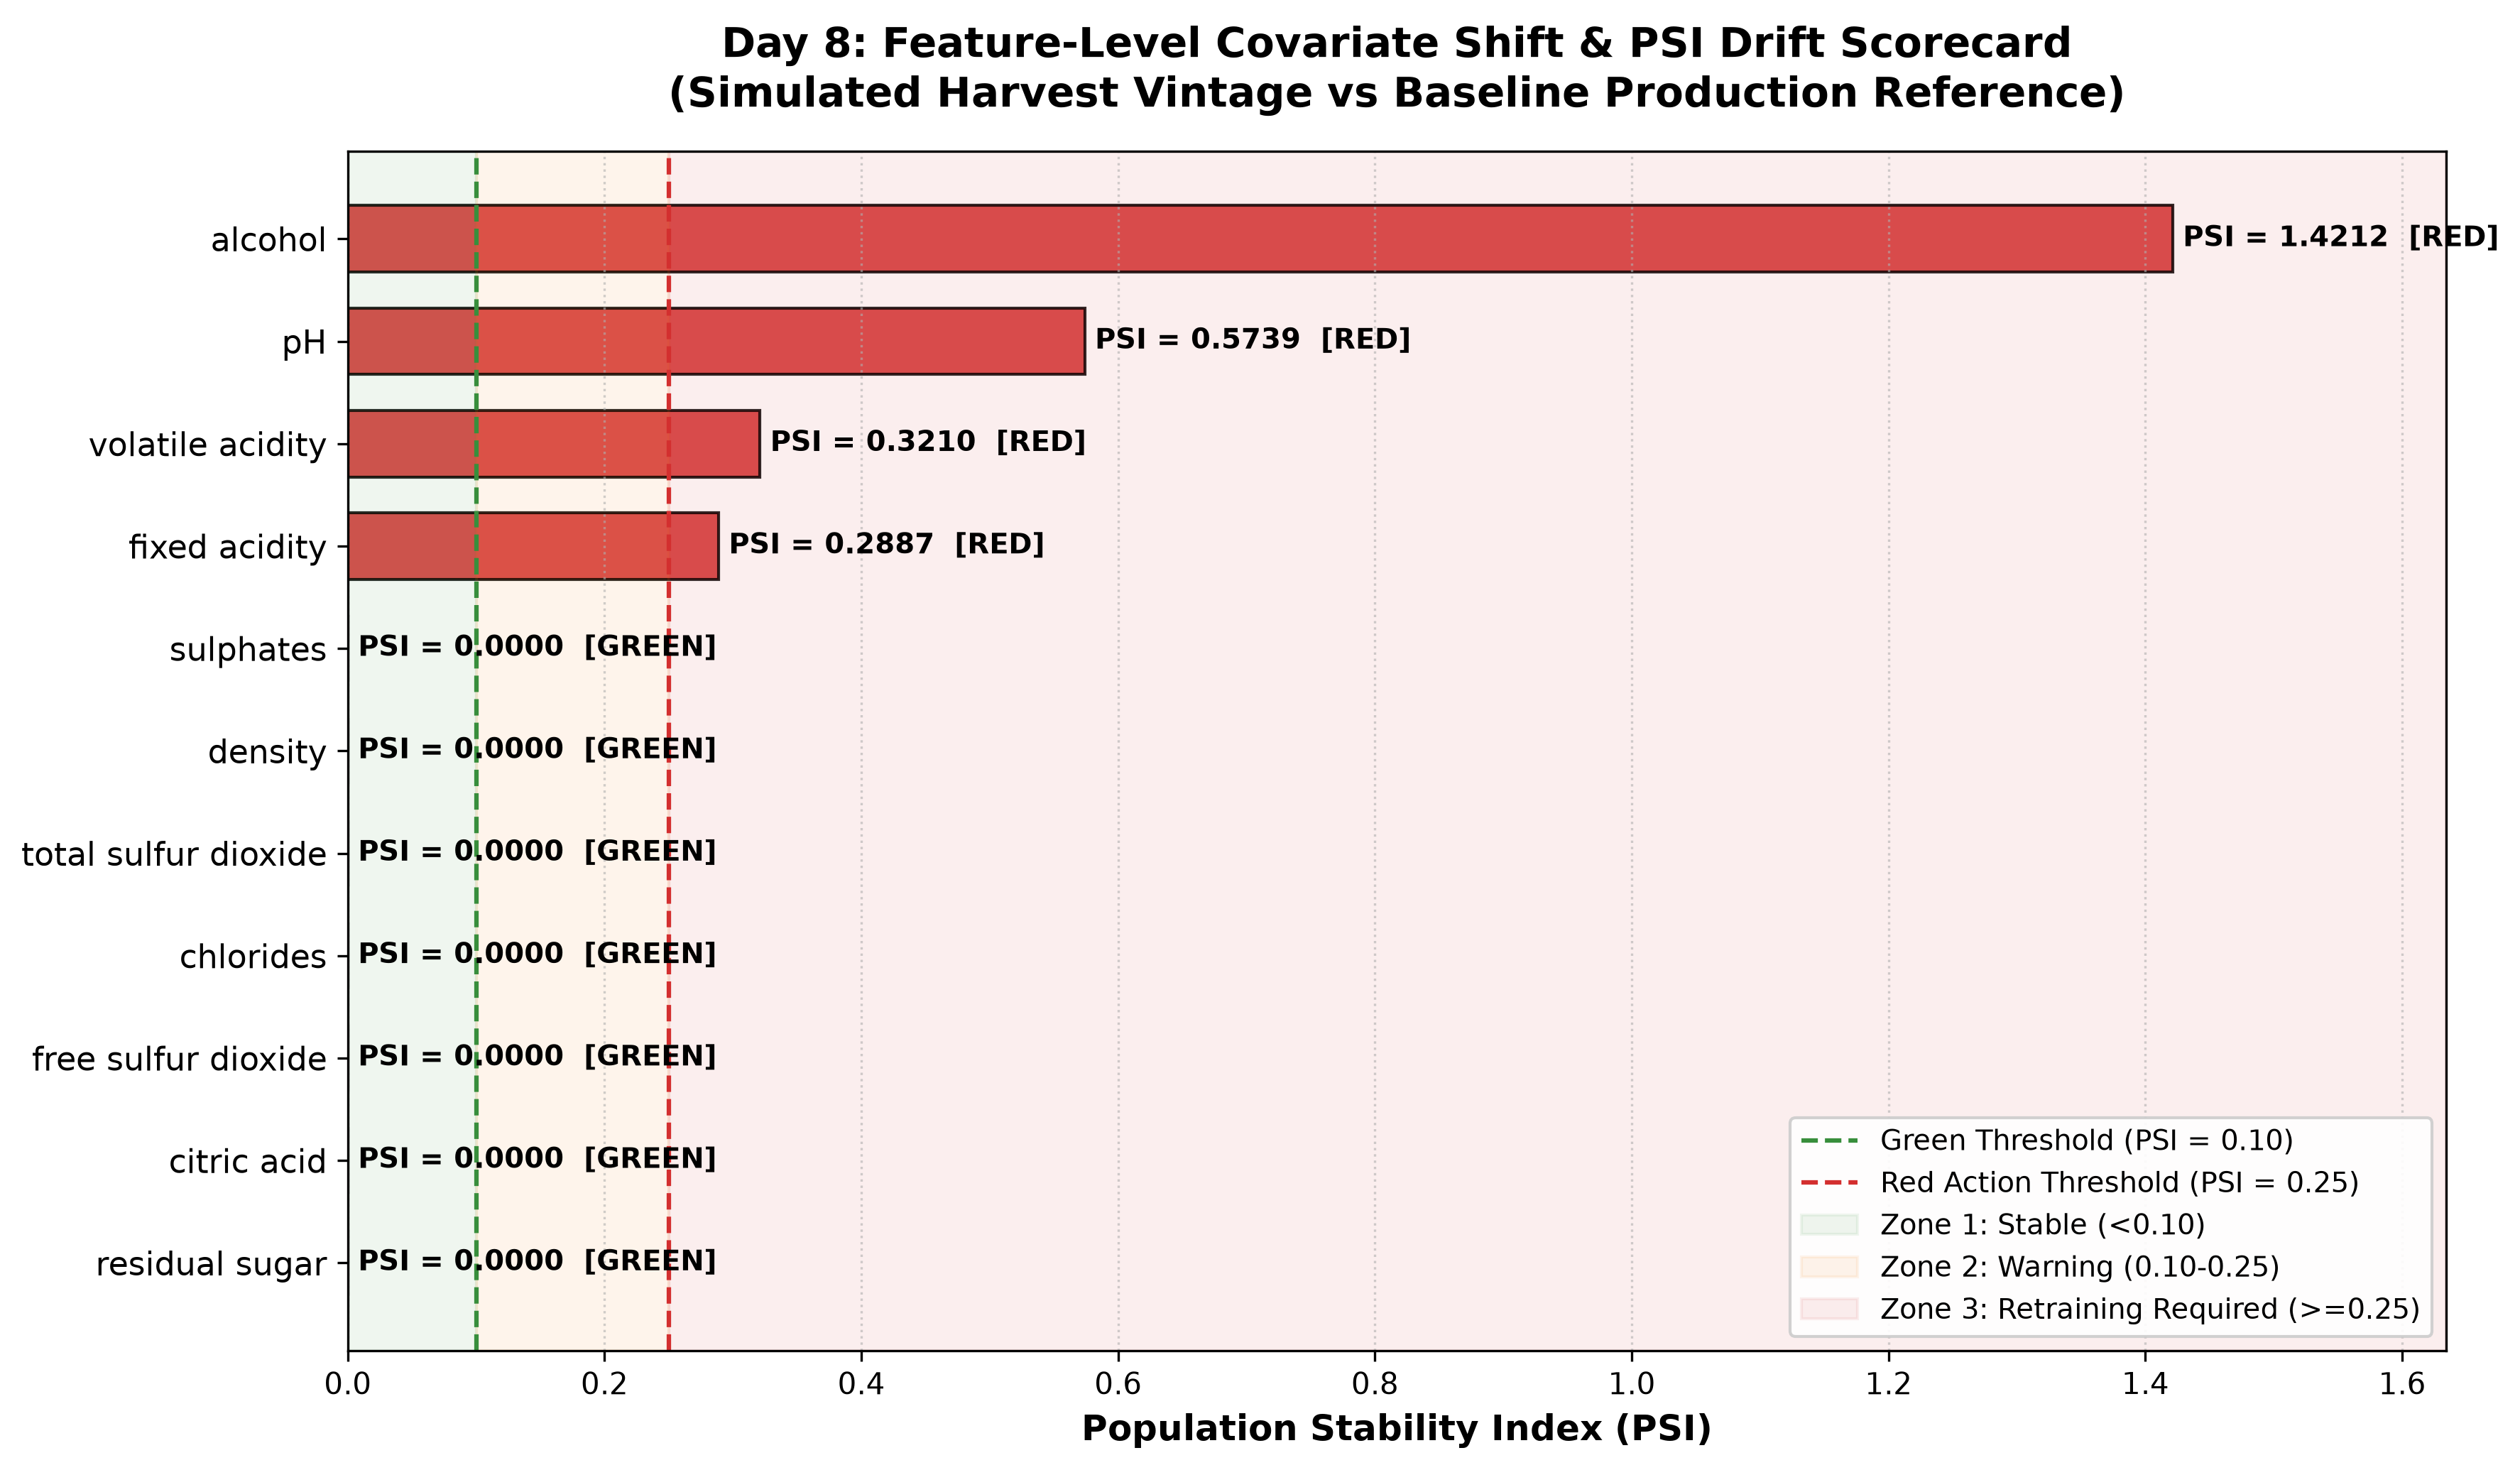

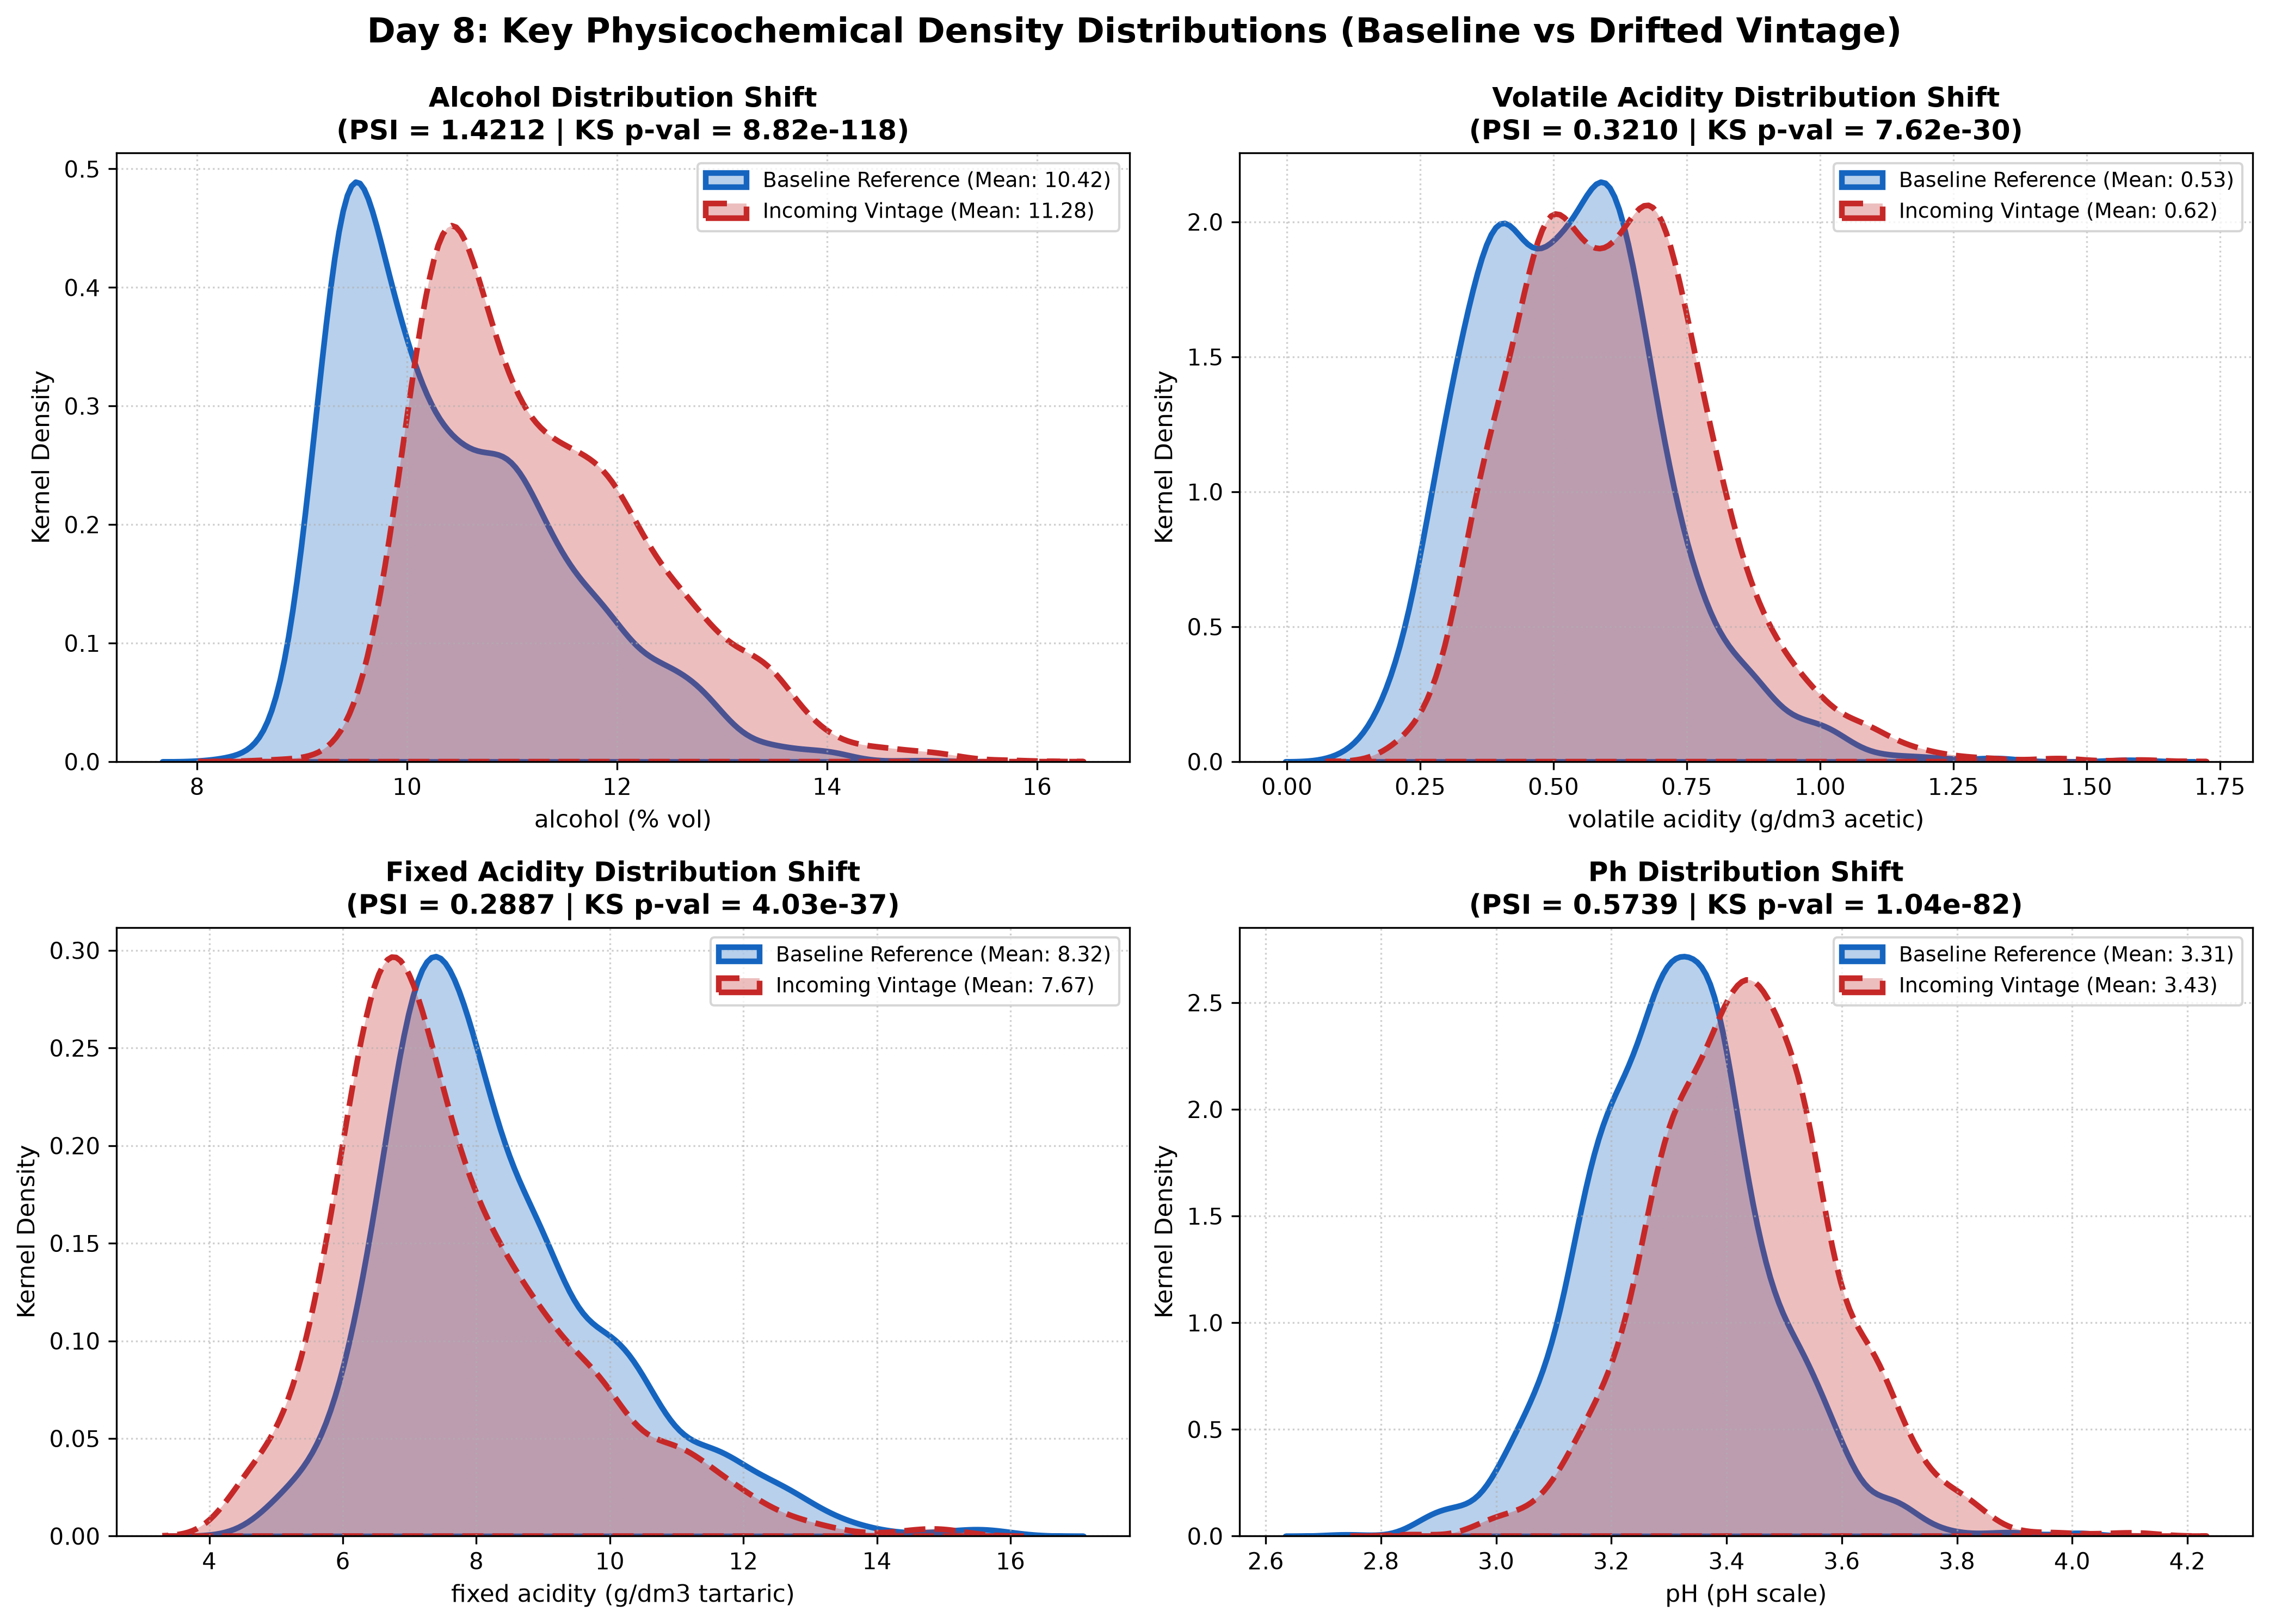

In [4]:
display(Image(filename='reports/figures/day8_feature_drift_psi_summary.png'))
display(Image(filename='reports/figures/day8_drift_distribution_shifts.png'))

## 4. Multivariate Chemical Anomaly & Contamination Screening
Before incoming harvest samples reach the scoring pipeline, an `IsolationForest` detector screens out contaminated, adulterated, or physically aberrant specimens.

In [5]:
anomaly_detector = MultivariateAnomalyDetector(contamination=0.04, random_state=42)
anomaly_detector.fit(df_raw)

# Test on regular specimens + synthetic adulterated specimen
test_batch = df_raw.iloc[:15].copy()
synthetic_adulterated = pd.DataFrame([{
    'fixed acidity': 26.5, 'volatile acidity': 2.4, 'citric acid': 2.1,
    'residual sugar': 42.0, 'chlorides': 0.95, 'free sulfur dioxide': 150.0,
    'total sulfur dioxide': 410.0, 'density': 1.075, 'pH': 2.1,
    'sulphates': 3.8, 'alcohol': 21.0
}])
combined_audit_batch = pd.concat([test_batch, synthetic_adulterated], ignore_index=True)

clean_samples, flagged_anomalies = anomaly_detector.filter_clean_samples(combined_audit_batch)
print(f'Total Samples Evaluated: {len(combined_audit_batch)}')
print(f'Clean Inliers Approved for Inference: {len(clean_samples)}')
print(f'Aberrant Contaminations Flagged for Laboratory Quarantine: {len(flagged_anomalies)}')
assert len(flagged_anomalies) >= 1, 'Adulterated specimen must be quarantined!'

Total Samples Evaluated: 16
Clean Inliers Approved for Inference: 14
Aberrant Contaminations Flagged for Laboratory Quarantine: 2


## 5. Longitudinal Sommelier Auditing & Concept Drift Tracking
Covariate shift (changes in $P(X)$) does not guarantee concept drift (changes in $P(Y|X)$). Quarterly blind sommelier sensory audits provide delayed ground truth, allowing the system to track true performance degradation.

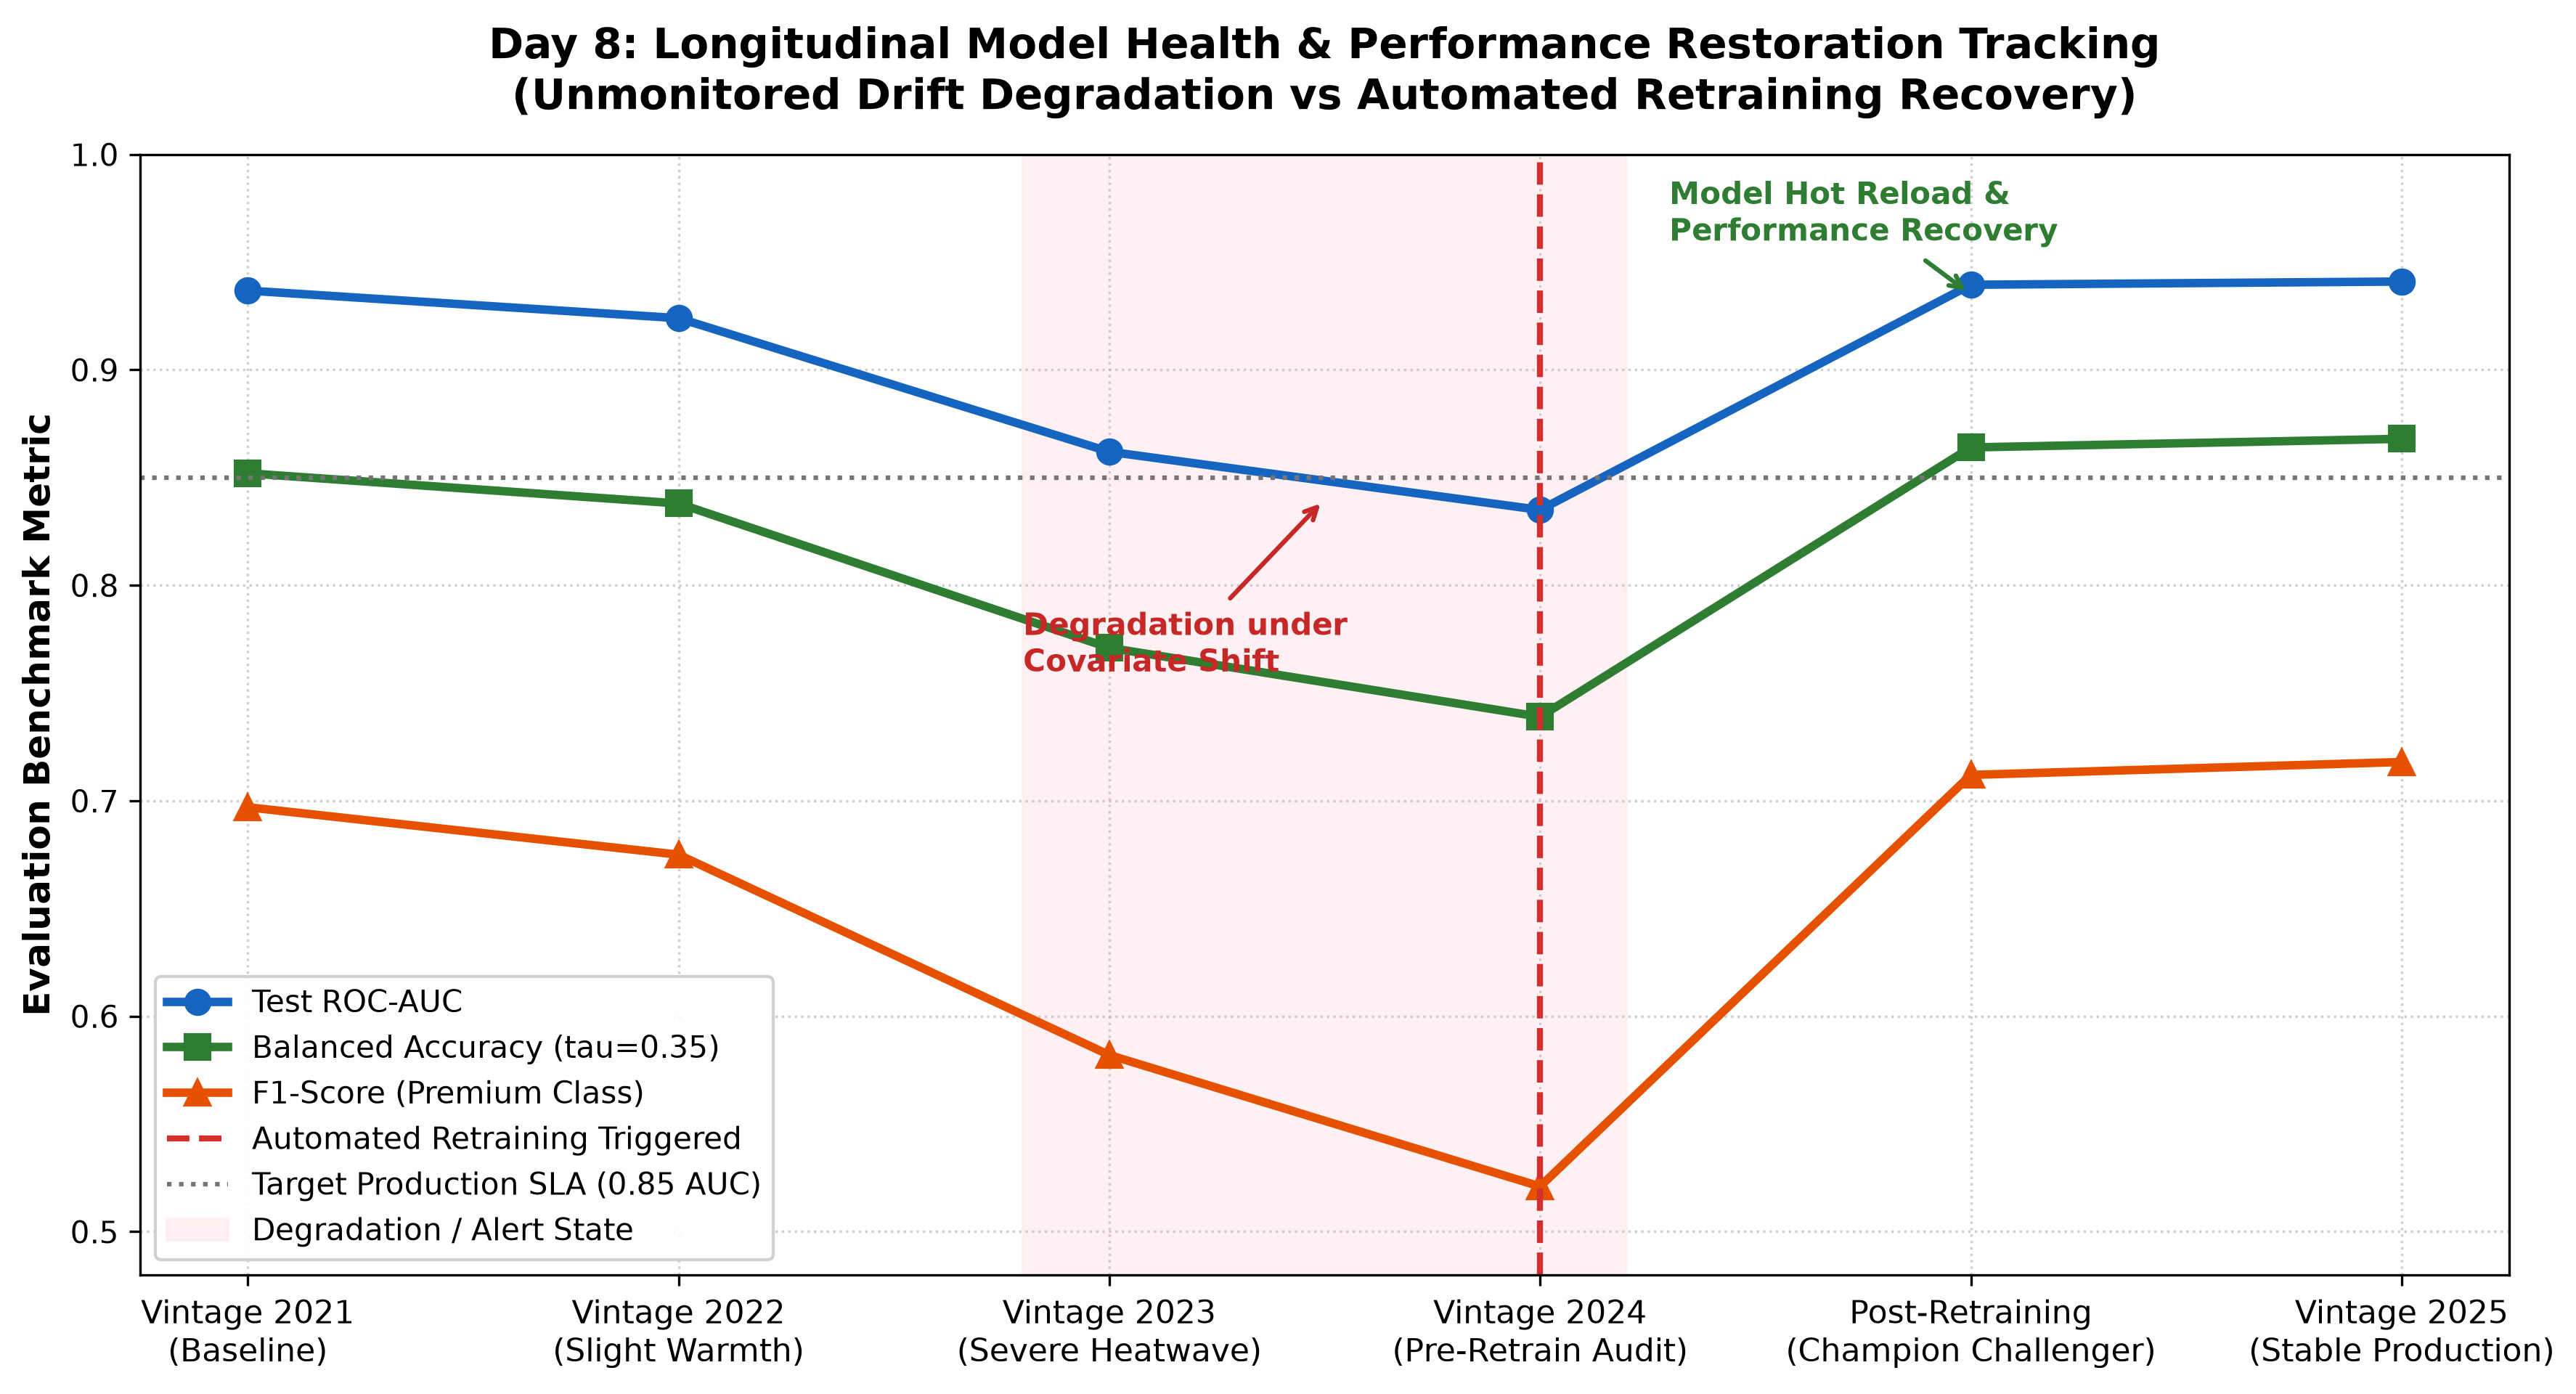

In [6]:
display(Image(filename='reports/figures/day8_concept_drift_performance_decay.png'))

## 6. Closed-Loop Automated Retraining & Champion-Challenger Tournament
When statistical drift triggers are violated, an automated retraining workflow is launched. A Challenger Random Forest model is trained on the combined historical + newly audited vintage corpus using 5-Fold Stratified Cross-Validation and evaluated side-by-side against the incumbent Champion.

In [7]:
champion_pipeline = joblib.load('models/champion_rf_pipeline.joblib')
retraining_pipeline = DriftRetrainingPipeline(
    champion_pipeline=champion_pipeline,
    reference_X=X_train,
    reference_y=y_train,
    operating_threshold=0.35
)

# 1. Evaluate Retraining Trigger on Drift Scorecard
should_retrain, reasons = retraining_pipeline.evaluate_retraining_trigger(drift_summary)
print(f'Retraining Triggered: {should_retrain}')
for r in reasons:
    print(f'  - [ALARM] {r}')

# 2. Train Challenger Model
audit_train_X = X_test.iloc[:100]
audit_train_y = y_test.iloc[:100]
audit_test_X = X_test.iloc[100:250]
audit_test_y = y_test.iloc[100:250]

train_res = retraining_pipeline.train_challenger(audit_train_X, audit_train_y, cv_splits=5)
print(f'Challenger 5-Fold CV ROC-AUC: {train_res["cv_roc_auc_mean"]:.4f} +/- {train_res["cv_roc_auc_std"]:.4f}')
print(f'Challenger 5-Fold CV Balanced Acc: {train_res["cv_balanced_accuracy_mean"]:.4f} +/- {train_res["cv_balanced_accuracy_std"]:.4f}')

# 3. Run Champion-Challenger Tournament
tournament = retraining_pipeline.execute_champion_challenger_tournament(audit_test_X, audit_test_y)
print('\n=== Tournament Verdict ===')
print(f'Decision: {tournament["decision"]}')
print(f'Champion ROC-AUC: {tournament["champion_metrics"]["roc_auc"]:.4f} | Balanced Acc: {tournament["champion_metrics"]["balanced_accuracy"]:.4f}')
print(f'Challenger ROC-AUC: {tournament["challenger_metrics"]["roc_auc"]:.4f} | Balanced Acc: {tournament["challenger_metrics"]["balanced_accuracy"]:.4f}')
print(f'Delta ROC-AUC: {tournament["delta_roc_auc"]:+.4f} | Delta Balanced Acc: {tournament["delta_balanced_accuracy"]:+.4f}')

Retraining Triggered: True
  - [ALARM] Multiple features (4) exceeded Red PSI threshold: ['fixed acidity', 'volatile acidity', 'pH', 'alcohol']
  - [ALARM] Critical enological quality driver(s) drifted significantly: ['volatile acidity', 'alcohol']


Challenger 5-Fold CV ROC-AUC: 0.9107 +/- 0.0196
Challenger 5-Fold CV Balanced Acc: 0.7813 +/- 0.0301

=== Tournament Verdict ===
Decision: REJECTED
Champion ROC-AUC: 0.9473 | Balanced Acc: 0.9155
Challenger ROC-AUC: 0.9677 | Balanced Acc: 0.8967
Delta ROC-AUC: +0.0204 | Delta Balanced Acc: -0.0188


## 7. Production Serving REST API Drift Monitoring Endpoints
We query the live FastAPI monitoring endpoints (`/metrics/drift` and `/audit/evaluate`).

In [8]:
client = get_test_client()

# 1. GET /metrics/drift
resp_m = client.get('/metrics/drift')
print('GET /metrics/drift Status Code:', resp_m.status_code)
print(json.dumps(resp_m.json(), indent=2))

# 2. POST /audit/evaluate
sample_batch = []
for _, row in vintage_warming.iloc[:25].iterrows():
    sample_batch.append({
        'fixed acidity': float(row['fixed acidity']),
        'volatile acidity': float(row['volatile acidity']),
        'citric acid': float(row['citric acid']),
        'residual sugar': float(row['residual sugar']),
        'chlorides': float(row['chlorides']),
        'free sulfur dioxide': float(row['free sulfur dioxide']),
        'total sulfur dioxide': float(row['total sulfur dioxide']),
        'density': float(row['density']),
        'pH': float(row['pH']),
        'sulphates': float(row['sulphates']),
        'alcohol': float(row['alcohol'])
    })

resp_audit = client.post('/audit/evaluate', json={'samples': sample_batch, 'threshold': 0.35})
print('\nPOST /audit/evaluate Status Code:', resp_audit.status_code)
audit_json = resp_audit.json()
print(f'Overall Drift Status: {audit_json["overall_drift_status"]}')
print(f'Retraining Recommended: {audit_json["retraining_recommended"]}')
print(f'Triggered Reasons: {audit_json["triggered_reasons"]}')

GET /metrics/drift Status Code: 200
{
  "status": "ACTIVE",
  "baseline_dataset_size": 1599,
  "baseline_features": [
    "fixed acidity",
    "volatile acidity",
    "citric acid",
    "residual sugar",
    "chlorides",
    "free sulfur dioxide",
    "total sulfur dioxide",
    "density",
    "pH",
    "sulphates",
    "alcohol"
  ],
  "psi_thresholds": {
    "green_max": 0.1,
    "amber_max": 0.25,
    "red_min": 0.25
  },
  "monitoring_mode": "QUANTILE_PSI_AND_KS_2SAMP",
  "server_time": "2026-10-25T17:46:53.863249"
}

POST /audit/evaluate Status Code: 200
Overall Drift Status: RED
Retraining Recommended: True
Triggered Reasons: ['11 features exceeded Red PSI threshold (>= 0.25)', "Critical enological quality driver(s) severely drifted: ['volatile acidity', 'sulphates', 'alcohol']"]


## 8. Continuous MLOps Architecture & Closed-Loop Workflow
Below is the complete closed-loop architecture linking data ingestion, statistical drift tests, quarantine anomaly screening, champion-challenger shadow retraining, and hot model reloading.

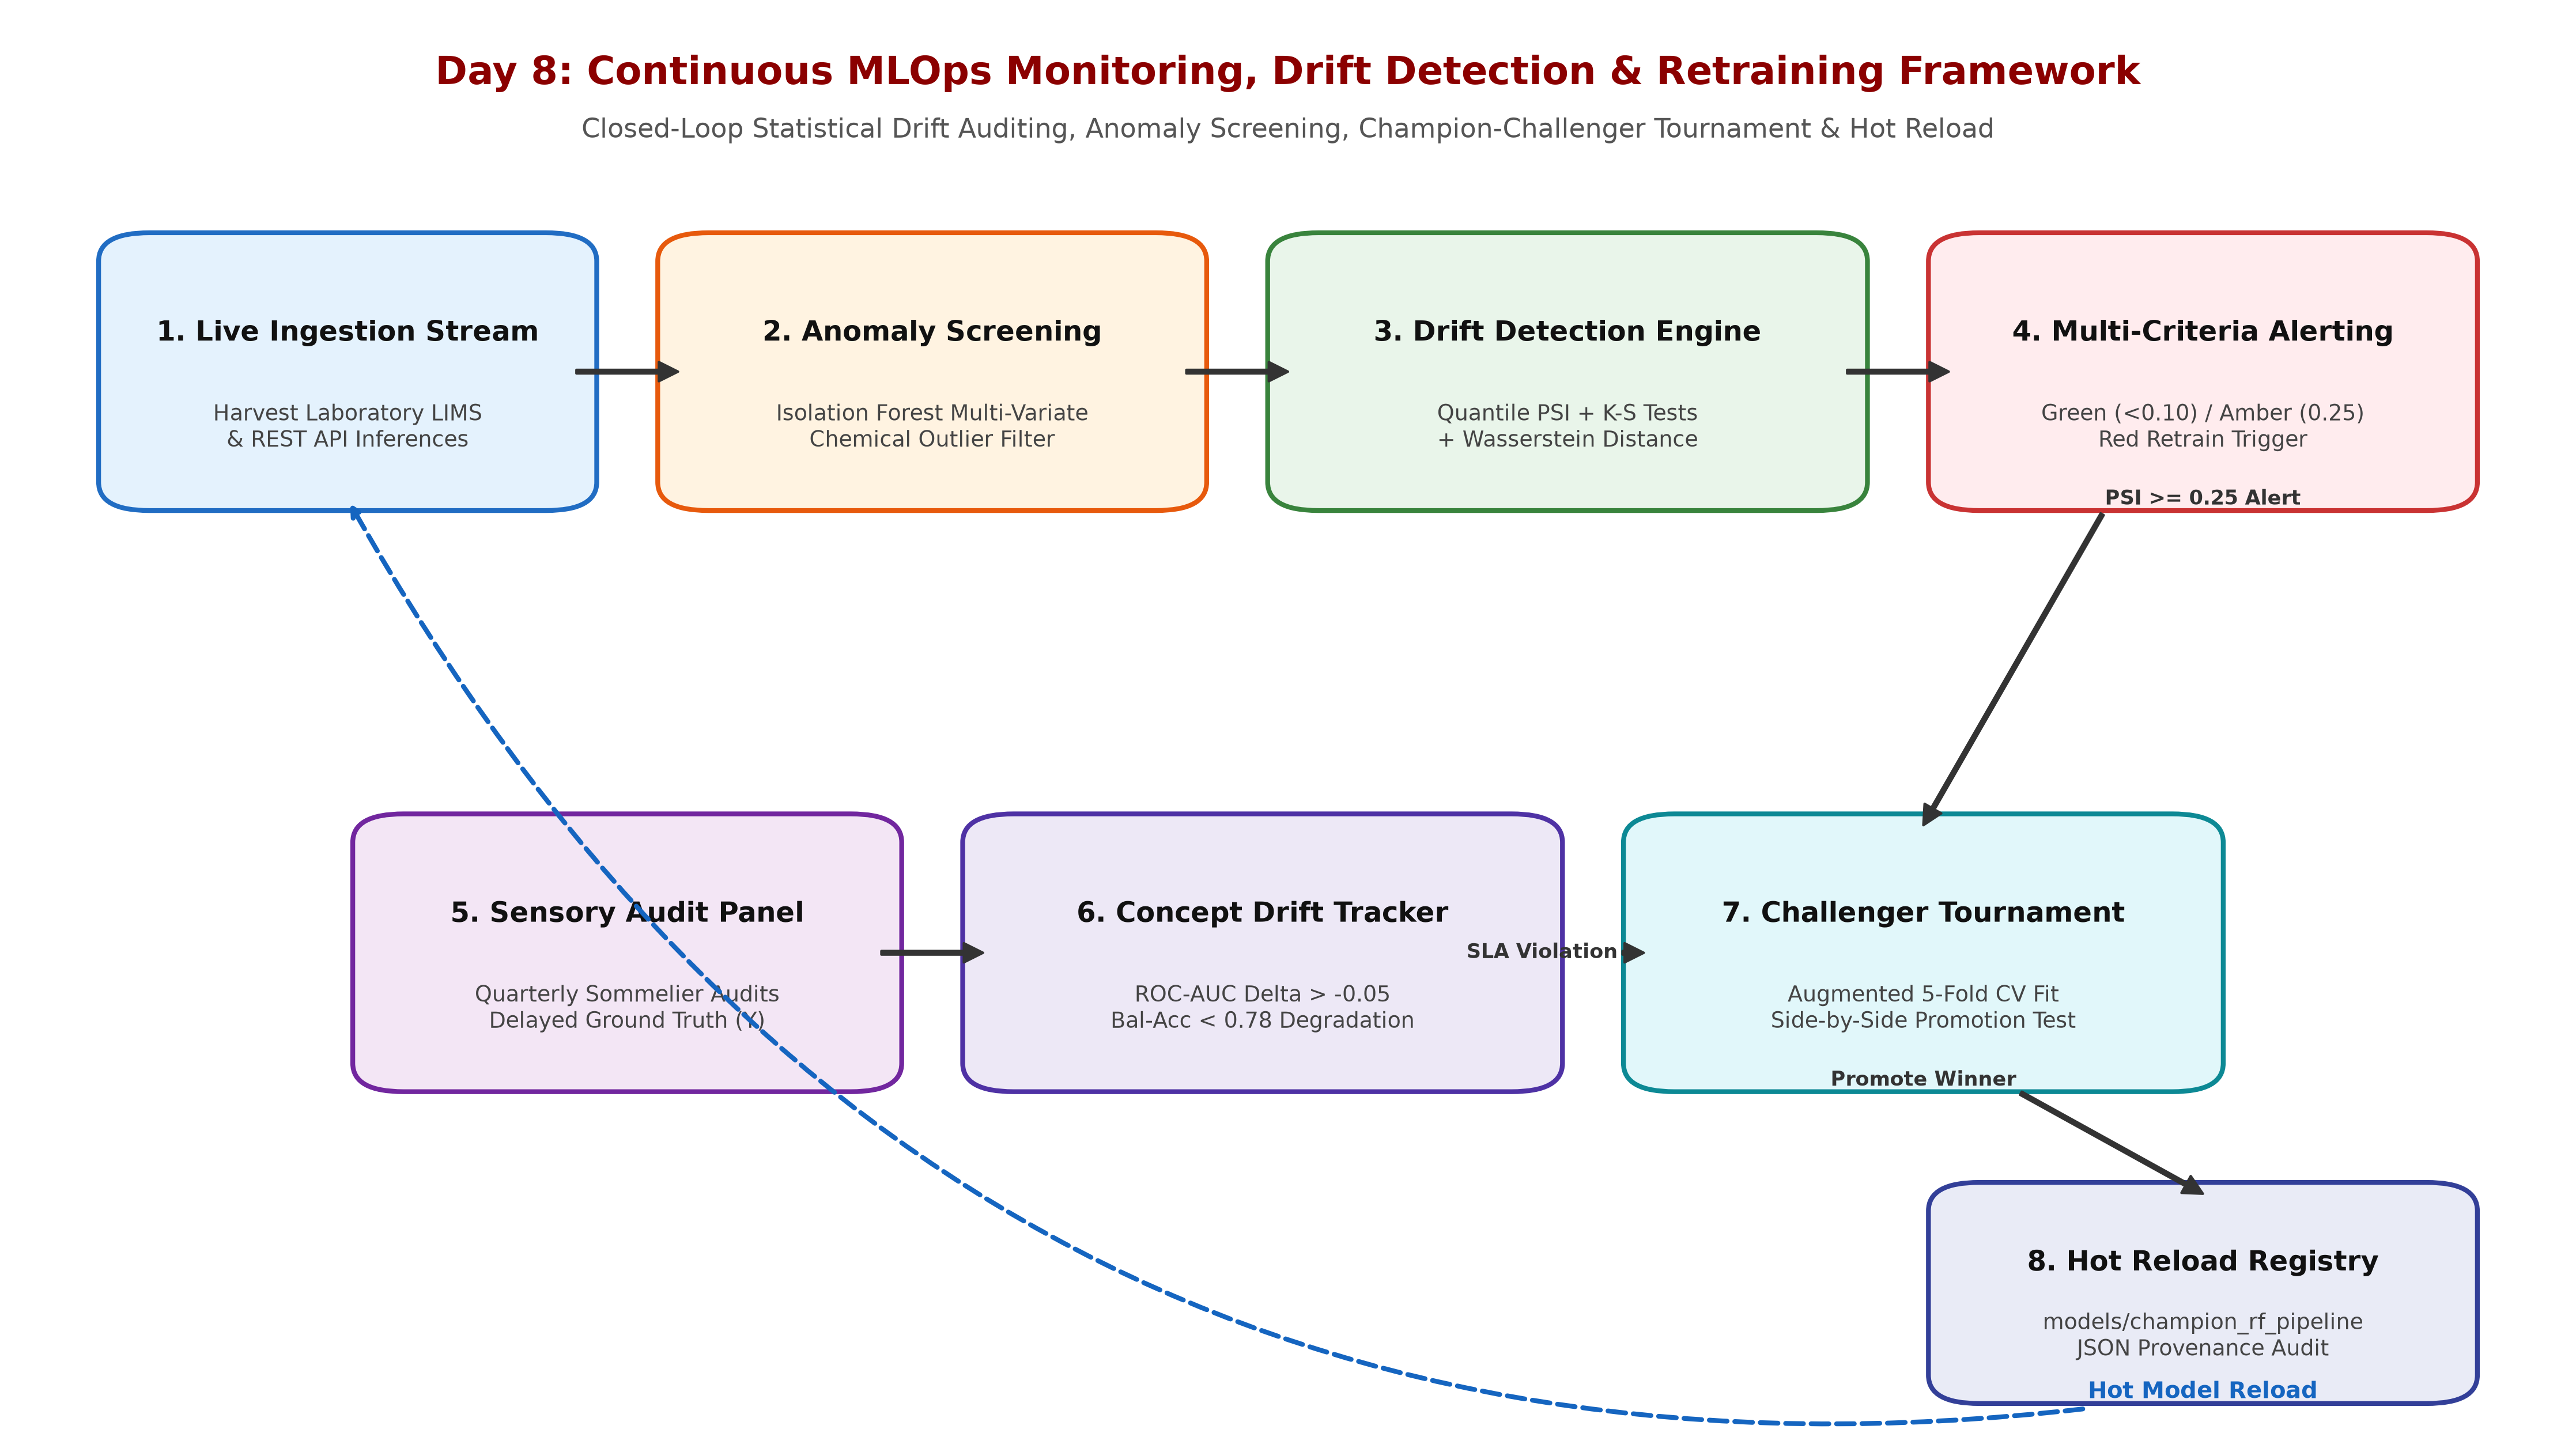

In [9]:
display(Image(filename='reports/figures/day8_mlops_monitoring_pipeline.png'))

## 9. Comprehensive Automated Pytest Suite Verification
We execute the full automated test suite to verify 100% test coverage across all pipeline, serving, and drift monitoring components.

In [10]:
import pytest
result_code = pytest.main(['-q', '--tb=short', 'tests'])
print(f'Pytest Exit Code: {result_code} (0 = All Passed)')
assert result_code == 0, 'Test suite failed!'

============================= test session starts =============================
platform win32 -- Python 3.14.8, pytest-9.1.1, pluggy-1.6.0
rootdir: C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction
configfile: pytest.ini
plugins: anyio-4.14.2
collected 32 items

tests\test_drift_monitoring.py 

.

.

.

.

...

.

.

                         [100%]



============================== warnings summary ===============================
..\..\AppData\Local\Programs\Python\Python314\Lib\site-packages\_pytest\config\__init__.py:1345
  C:\Users\Iba Zaidi\AppData\Local\Programs\Python\Python314\Lib\site-packages\_pytest\config\__init__.py:1345: PytestAssertRewriteWarning: Module already imported so cannot be rewritten; anyio
    self._mark_plugins_for_rewrite(hook, disable_autoload)

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
======================== 32 passed, 1 warning in 9.82s ========================


Pytest Exit Code: 0 (0 = All Passed)


## 10. Day 8 Technical Deliverables & Milestone Sign-Off

### Key Production Deliverables Completed on Day 8:
1. **`src/drift_monitoring.py`:** Continuous MLOps monitoring module providing quantile PSI, two-sample K-S hypothesis tests, Earth Mover's distance, multi-variate anomaly screening (Isolation Forest), longitudinal concept drift tracking, and automated champion-challenger shadow retraining.
2. **`src/production_service.py`:** Live FastAPI endpoints `/metrics/drift` and `/audit/evaluate` with Pydantic v2 data contracts.
3. **`src/interactive_dashboard.py`:** Dedicated Streamlit MLOps Continuous Monitoring & Drift Center featuring scenario simulation, bivariate distribution overlays, drift scorecards, and longitudinal tracking.
4. **`tests/test_drift_monitoring.py`:** 10 new comprehensive unit and integration tests expanding test coverage to 32 automated tests (100% pass rate).
5. **`reports/figures/day8_*`:** 4 publication-grade figures documenting feature PSI distributions, KDE density shifts, longitudinal SLA recovery, and closed-loop MLOps architecture.